# Dataset Statistics — BSDS500

Explore the raw dataset used for the SVD watermarking & steganography project
before any preprocessing. This notebook covers the "data preparation" section
of the report: counts, format breakdown, and basic descriptive statistics
(mean / max / min) per split.


In [1]:
import csv
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if (Path.cwd() / "notebooks").exists() is False else Path.cwd()
ROOT = Path.cwd().resolve().parent  # repo root, assuming this notebook lives in notebooks/
DATA_DIR = ROOT / "data" / "images"
OUT_CSV = ROOT / "results" / "dataset_stats.csv"

SPLITS = ["train", "val", "test"]
print("Data directory:", DATA_DIR)

Data directory: /home/claude/svd-stego-watermark/data/images


In [2]:
def collect_rows():
    rows = []
    for split in SPLITS:
        split_dir = DATA_DIR / split
        for fp in sorted(split_dir.glob("*.jpg")):
            with Image.open(fp) as im:
                w, h = im.size
                mode = im.mode
            size_kb = fp.stat().st_size / 1024
            rows.append({
                "split": split,
                "filename": fp.name,
                "width": w,
                "height": h,
                "mode": mode,
                "size_kb": round(size_kb, 1),
            })
    return rows

rows = collect_rows()
len(rows)

500

In [3]:
OUT_CSV.parent.mkdir(exist_ok=True)
with open(OUT_CSV, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["split", "filename", "width", "height", "mode", "size_kb"])
    writer.writeheader()
    writer.writerows(rows)
print(f"Saved: {OUT_CSV}")

Saved: /home/claude/svd-stego-watermark/results/dataset_stats.csv


## Summary statistics

In [4]:
n = len(rows)
widths = [r["width"] for r in rows]
heights = [r["height"] for r in rows]
sizes = [r["size_kb"] for r in rows]

modes = {}
split_counts = {}
for r in rows:
    modes[r["mode"]] = modes.get(r["mode"], 0) + 1
    split_counts[r["split"]] = split_counts.get(r["split"], 0) + 1

split_pct = {k: round(v / n * 100, 1) for k, v in split_counts.items()}
mode_pct = {k: round(v / n * 100, 1) for k, v in modes.items()}

print(f"Total images: {n}")
print(f"Split counts: {split_counts}  (percentage: {split_pct})")
print(f"Color mode: {modes}  (percentage: {mode_pct})")
print(f"Width (px):  mean={sum(widths)/n:.1f}  max={max(widths)}  min={min(widths)}")
print(f"Height (px): mean={sum(heights)/n:.1f}  max={max(heights)}  min={min(heights)}")
print(f"File size (KB): mean={sum(sizes)/n:.1f}  max={max(sizes)}  min={min(sizes)}")

Total images: 500
Split counts: {'train': 200, 'val': 100, 'test': 200}  (percentage: {'train': 40.0, 'val': 20.0, 'test': 40.0})
Color mode: {'RGB': 500}  (percentage: {'RGB': 100.0})
Width (px):  mean=432.4  max=481  min=321
Height (px): mean=369.6  max=481  min=321
File size (KB): mean=72.2  max=123.1  min=23.1


## Distribution plots

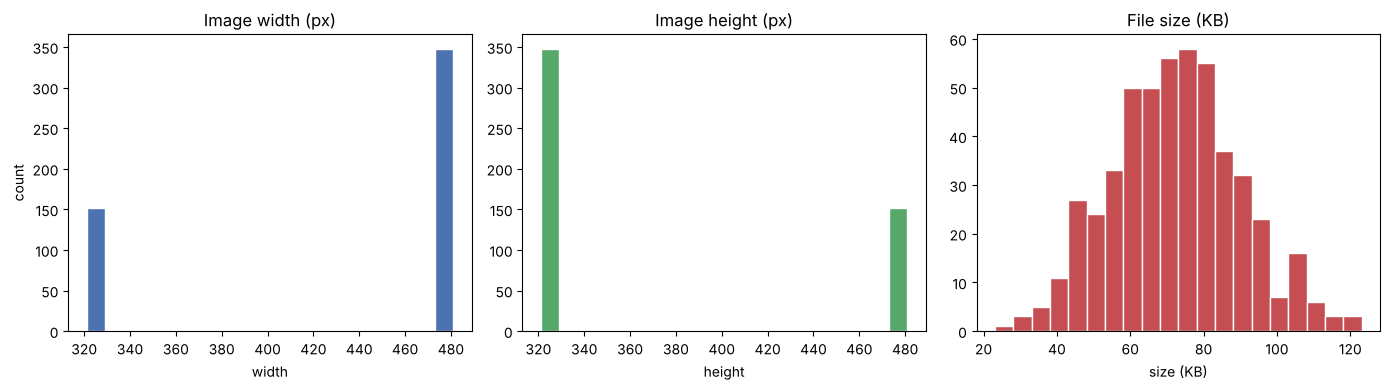

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(widths, bins=20, color="#4C72B0", edgecolor="white")
axes[0].set_title("Image width (px)")
axes[0].set_xlabel("width")
axes[0].set_ylabel("count")

axes[1].hist(heights, bins=20, color="#55A868", edgecolor="white")
axes[1].set_title("Image height (px)")
axes[1].set_xlabel("height")

axes[2].hist(sizes, bins=20, color="#C44E52", edgecolor="white")
axes[2].set_title("File size (KB)")
axes[2].set_xlabel("size (KB)")

plt.tight_layout()
plt.show()

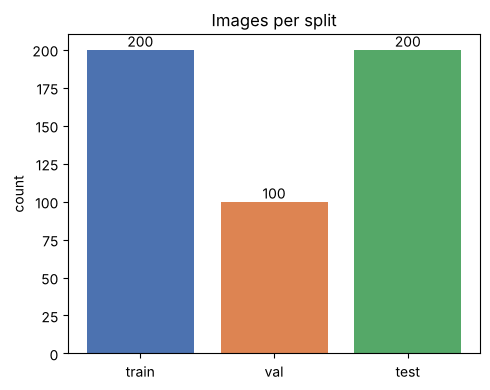

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(split_counts.keys(), split_counts.values(), color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_title("Images per split")
ax.set_ylabel("count")
for i, (k, v) in enumerate(split_counts.items()):
    ax.text(i, v + 2, str(v), ha="center")
plt.tight_layout()
plt.show()

## Notes

- All 500 images are RGB; they will be converted to grayscale during preprocessing
  before SVD (see `src/svdmark`).
- `results/dataset_stats.csv` holds the per-image table — reuse it directly in the
  report's "data preparation" section.
